<a href="https://colab.research.google.com/github/mamunh9/Autonomous-Systems-Lab/blob/main/DLFundamentals01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning Fundamentals — Intro Notebook
**Autonomous Systems B (2-week self-study block)**

This notebook introduces the core ideas needed for the first deep-learning lab:

- tensors and image shapes,
- feedforward neural networks,
- training loops and backpropagation,
- convolutional neural networks,
- hyperparameter experiments,
- reproducible scientific work.

The notebook is organized by **Week 1** and **Week 2**. Section 9 is an **optional extension / Week 3** topic.

> **Prerequisites:** basic Python, arrays, linear algebra, derivatives, and probability.  
> If Python/NumPy/PyTorch are new to you, review the course slides **DL 02 Python** before starting.

### Environment and reproducibility
Run the notebook **top-to-bottom**. Keep outputs visible and record the software versions used for your experiment.

In [4]:
import random
import sys
import numpy as np
import torch
import torchvision

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Seed:", SEED)

Python: 3.13.16
PyTorch: 2.11.0+cpu
torchvision: 0.26.0+cpu
Device: cpu
Seed: 42


---
# Week 1 — Foundations

## 1. Tensors & Arrays

**Concept:** Images are arrays. In PyTorch, image batches are usually represented as

$$
(N, C, H, W),
$$

where:

- $N$ = batch size,
- $C$ = number of channels,
- $H$ = image height,
- $W$ = image width.

A grayscale MNIST image has one channel, while an RGB image has three channels.

**Task 1.1 (Explain):**
- Given a batch shaped `(N, C, H, W)`, explain what each letter stands for.
- What shapes would you expect for grayscale vs. RGB images?

### Self-study checkpoint
Before continuing, make sure you can explain why a batch of 64 MNIST images has shape

$$
(64, 1, 28, 28).
$$

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 2 (Preliminaries), especially Sec. 2.1 Data Manipulation**: https://d2l.ai/

**Optional reading**
- Prince, *Understanding Deep Learning*, **Appendix B (Math)**; probability background is in **Appendix C**: https://udlbook.github.io/udlbook/

In [5]:
img = torch.rand(28, 28)
print("Single grayscale image:", img.shape)

batch = torch.rand(64, 1, 28, 28)
print("Batch of grayscale images:", batch.shape)

rgb = torch.rand(16, 3, 64, 64)
print("Batch of RGB images:", rgb.shape)

Single grayscale image: torch.Size([28, 28])
Batch of grayscale images: torch.Size([64, 1, 28, 28])
Batch of RGB images: torch.Size([16, 3, 64, 64])


**Your answer — Task 1.1**

_Write 3–5 sentences here._
  
  N = batch size, C= number of channels, H = image height and W = image width.Grayscale images have one channel and RGB images have three channels. A batch of 64 grayscale MNIST images has the shape (64, 1, 28, 28). A batch of 16 RGB images with a height and width of 64 pixels has the shape (16, 3, 64, 64).

## 2. Feedforward Neural Networks (FFNN)

A hidden layer applies an affine transformation followed by a nonlinear activation. For a **row-vector** input,

$$
z = xW + b,
$$

followed by

$$
h = \phi(z).
$$

With ReLU,

$$
\phi(z) = \max(0,z).
$$

The nonlinearity is essential: several affine/linear layers without a nonlinear activation can be collapsed into one affine transformation.

> **PyTorch notation note:** In the mathematical row-vector convention above, $W$ has shape `(in_features, out_features)`.  
> `nn.Linear` stores its parameter as `weight` with shape `(out_features, in_features)` and internally computes
>
> $$
> y = xW^\top + b.
> $$
>
> Therefore, the matrix dimensions in the derivation and the shape of `layer.weight` appear transposed.

The final classification layer is usually left **without** an activation when using `nn.CrossEntropyLoss()`, because the loss expects raw **logits**.

**Task 2.1 (Reasoning):**
- Why do we need a nonlinear activation between hidden layers?
- How does matrix multiplication appear in a neural network?
- What happens if all activations are removed?

In [6]:
import torch.nn as nn

def make_ffnn():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 128),
        nn.ReLU(),
        nn.Linear(128, 10)
    )

ffnn = make_ffnn()
ffnn

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)

### 2.2 From Linear Scores to Probabilities — Logits, Softmax, and Cross-Entropy

The final layer produces **logits**

$$
o = [o_1,\ldots,o_K].
$$

Softmax converts the logits into class probabilities:

$$
p_k
=
\frac{\exp(o_k)}
{\sum_{j=1}^{K}\exp(o_j)}.
$$

For one-hot targets, multiclass cross-entropy is

$$
\mathcal{L}
=
-\sum_{k=1}^{K}
y_k \log(p_k).
$$

Because only the correct class has target value $1$, this reduces to

$$
\mathcal{L}
=
-\log(p_y).
$$

Cross-entropy can also be interpreted as a **negative log-likelihood** for the correct class.

> **Important PyTorch detail:** `nn.CrossEntropyLoss()` expects raw logits. Do **not** add a `Softmax()` layer before it.

### Differences you will notice in Géron
Géron's Keras/TensorFlow examples often use:
- image layouts in **NHWC** form rather than PyTorch's typical **NCHW**,
- an explicit softmax output layer in model definitions.

In this notebook, PyTorch uses **NCHW** tensors and `CrossEntropyLoss()` receives raw logits.

**Task 2.2 (Reasoning):**
- Why is the denominator of softmax shared across all classes?
- Why does cross-entropy become large when the correct class receives a very small probability?
- Why should we not apply softmax before `CrossEntropyLoss()`?

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 4, especially Sec. 4.1 and 4.4–4.5**: https://d2l.ai/
- Géron, *Hands-On Machine Learning*, **Ch. 10**.

**Optional reading**
- Goodfellow, Bengio & Courville, *Deep Learning*, **Ch. 6**: https://www.deeplearningbook.org/
- Prince, *Understanding Deep Learning*, **Ch. 5 (Loss Functions)**: https://udlbook.github.io/udlbook/

### 2.3 Shape Trace Through the FFNN

For a batch of 64 MNIST images:

$$
(64,1,28,28)
\rightarrow
(64,784)
\rightarrow
(64,128)
\rightarrow
(64,10).
$$

Interpretation:
1. `Flatten()` converts each image into 784 features.
2. `Linear(784, 128)` produces 128 hidden features.
3. `ReLU()` changes values but **not shape**.
4. `Linear(128, 10)` produces one logit for each class.

**Task 2.3:**
- Which dimensions come from the dataset?
- Which dimensions are design choices?
- What is the PyTorch shape of the first layer's `weight` tensor?

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 5, especially Sec. 5.1–5.2**: https://d2l.ai/

**Optional reading**
- Géron, *Hands-On Machine Learning*, **Ch. 10**.
- Prince, *Understanding Deep Learning*, **Ch. 3–4**.

**Your answer — Tasks 2.1–2.3**

_Write your explanation here. Include the expected PyTorch weight shape for `Linear(784,128)`._


Task 2.1

1.Because a nonlinear activation function enables a network to learn complex patterns and nonlinear relationships in data.

2.Matrix multiplication appear in a neural network as z=xW+b where, x represents the input, W is the weight matrix and b is the bias vector.

3.The entire network loses the ability to model nonlinear relationships and becomes equivalent to a linear classifier.

Task 2.2
1. The denominator normalizes the scores so that every class receives a probability between 0 and 1 and all class probabilities sum to 1.
2. Because Cross-entropy $\mathcal{L} = -\log(p_y)$ where, $\mathcal p_y$is the predicted probability.
3. Because nn.CrossEntropyLoss() in PyTorch already combines LogSoftmax and NLLLoss internally.

Task 2.3
1. The dimensions come from the dataset are (64, 1, 28, 28).
2. The hidden-layer width of 128 is a design choice.
3. The weight tensor shape is (128, 784).

## 3. Training Loop & Backpropagation

A basic training step consists of:

1. forward pass,
2. compute the loss,
3. clear old gradients,
4. backpropagate,
5. update parameters.

We also create a **validation set**. Hyperparameters should be selected using validation data; the test set should be kept for the final performance estimate.

For MNIST, the classes are approximately balanced, not perfectly balanced.

### Input scaling
`ToTensor()` maps pixel values from integers in $[0,255]$ to floating-point values in $[0,1]$. For more demanding tasks, additional mean/std normalization is often useful, but it is not essential for this introductory MNIST example.

In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torch.optim as optim
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()

full_train_ds = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_ds = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

split_gen = torch.Generator().manual_seed(SEED)
train_ds, val_ds = random_split(
    full_train_ds, [55_000, 5_000], generator=split_gen
)

def make_loaders(batch_size=64, seed=SEED):
    loader_gen = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_ds, batch_size=batch_size, shuffle=True,
        generator=loader_gen, num_workers=0
    )
    val_loader = DataLoader(
        val_ds, batch_size=256, shuffle=False, num_workers=0
    )
    test_loader = DataLoader(
        test_ds, batch_size=256, shuffle=False, num_workers=0
    )
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 455kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.91MB/s]


In [8]:
def evaluate(model, loader, loss_fn=None):
    model.eval()
    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)

            if loss_fn is not None:
                total_loss += loss_fn(logits, y).item() * y.size(0)

            pred = logits.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)

    metrics = {"accuracy": correct / total}
    if loss_fn is not None:
        metrics["loss"] = total_loss / total
    return metrics


def train_model(model_fn, lr=0.05, epochs=3, batch_size=64,
                seed=SEED, optimizer_name="sgd",
                train_loader=None, val_loader=None):
    # A fresh model is created for every run.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    if train_loader is None or val_loader is None:
        train_loader, val_loader, _ = make_loaders(
            batch_size=batch_size, seed=seed
        )

    model = model_fn().to(device)
    loss_fn = nn.CrossEntropyLoss()

    if optimizer_name.lower() == "adam":
        optimizer = optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": []
    }

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for X, y in train_loader:
            X, y = X.to(device), y.to(device)

            logits = model(X)
            loss = loss_fn(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        val_metrics = evaluate(model, val_loader, loss_fn)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])

        print(
            f"Epoch {epoch+1:02d} | "
            f"train loss={train_loss:.4f} | "
            f"val loss={val_metrics['loss']:.4f} | "
            f"val acc={100*val_metrics['accuracy']:.2f}%"
        )

    return model, history

### Task 3.1 — Train the FFNN

Train for at least 3 epochs and plot:
- training loss,
- validation accuracy.

Then evaluate the model **once** on the test set.

Epoch 01 | train loss=0.5872 | val loss=0.3623 | val acc=89.40%
Epoch 02 | train loss=0.3002 | val loss=0.2886 | val acc=91.36%
Epoch 03 | train loss=0.2487 | val loss=0.2418 | val acc=92.90%


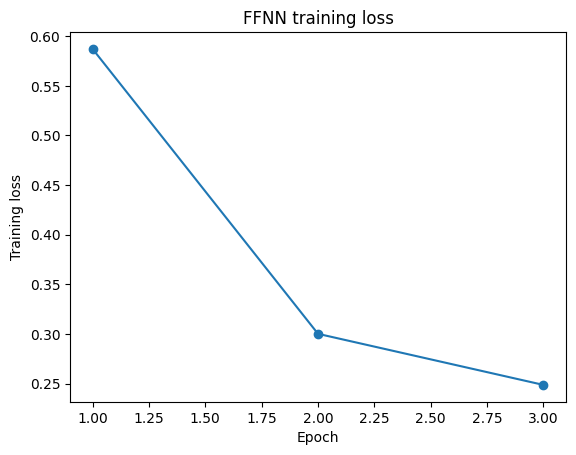

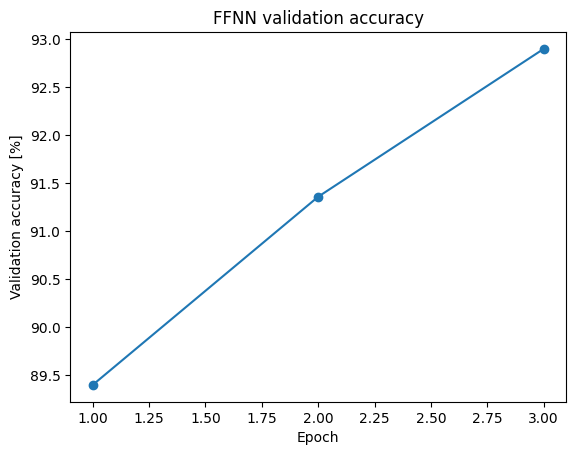

Final FFNN test accuracy: 93.55%


In [9]:
BASE_LR = 0.05

ffnn_model, ffnn_history = train_model(
    make_ffnn, lr=BASE_LR, epochs=3, seed=SEED
)

epochs = range(1, len(ffnn_history["train_loss"]) + 1)

plt.figure()
plt.plot(epochs, ffnn_history["train_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("FFNN training loss")
plt.show()

plt.figure()
plt.plot(
    epochs,
    [100*a for a in ffnn_history["val_accuracy"]],
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy [%]")
plt.title("FFNN validation accuracy")
plt.show()

ffnn_test = evaluate(ffnn_model, test_loader)
print(f"Final FFNN test accuracy: {100*ffnn_test['accuracy']:.2f}%")

> **Test-set discipline:** This baseline test result is a descriptive check only. Do **not** use it to choose the learning rate, batch size, architecture, or other hyperparameters. Make those choices from validation results.

### 3.2 Computational Graphs, the Chain Rule, and Autograd

A neural network can be interpreted as a composition of functions:

$$
x
\rightarrow
z
\rightarrow
h
\rightarrow
o
\rightarrow
\mathcal{L}.
$$

Backpropagation applies the **chain rule** from the loss backward through this graph.

In PyTorch, `loss.backward()` computes gradients for parameters with `requires_grad=True`.

For example, `ffnn_model[1].weight.grad.shape` returns `(128, 784)` because PyTorch stores `Linear.weight` as `(out_features, in_features)`.

**Task 3.2:**
- Inspect the gradient shape of the first linear layer.
- Explain why it is `(128, 784)` although the row-vector derivation later uses a matrix in $\mathbb{R}^{784\times128}$.
- What happens if `optimizer.zero_grad()` is omitted?

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Sec. 5.3**: https://d2l.ai/

**Optional reading**
- Goodfellow et al., *Deep Learning*, **Sec. 6.5**.
- Paszke et al. (2019), PyTorch paper: https://arxiv.org/abs/1912.01703
- Prince, *Understanding Deep Learning*, **Ch. 7**.

**Your answer — Tasks 3.1–3.2**

_Write your interpretation of the curves and gradient-shape result here._

Task 3.1

Training loss decreased, validation accuracy increased and the final test accuracy is 93.55 percent.

Task 3.2
1. The first linear layer's weight has shape (128, 784) and its gradient has the same shape.
2. Because PyTorch stores weight as (out_features, in_features) and computes
$xW^\top + b$ internally, which is the transpose of the row-vector convention.
3. PyTorch accumulates gradients instead of clearing them. This leads to incorrect, rapidly growing gradient values and unstable training.
  



## 4. Math Deep Dive — Backpropagation (Week 1)

We derive gradients for a **1-hidden-layer** classifier.

To avoid reusing the same symbol for two different meanings, let $m$ denote the hidden-layer width.

**Model (row-vector convention):**

- Input: $x \in \mathbb{R}^{d}$
- Hidden pre-activation:

$$
z = xW_1 + b_1,
$$

with

$$
W_1 \in \mathbb{R}^{d\times m},
\qquad
b_1 \in \mathbb{R}^{m}.
$$

- Hidden activation:

$$
h = \phi(z)
$$

- Logits:

$$
o = hW_2 + b_2,
$$

with

$$
W_2 \in \mathbb{R}^{m\times K},
\qquad
b_2 \in \mathbb{R}^{K}.
$$

- Probabilities:

$$
p = \mathrm{softmax}(o).
$$

For one sample with class label $y$,

$$
\mathcal{L} = -\log p_y.
$$

### Gradients

$$
\frac{\partial \mathcal{L}}{\partial o}
=
p - y_{\text{onehot}}.
$$

$$
\frac{\partial \mathcal{L}}{\partial W_2}
=
h^\top
\frac{\partial \mathcal{L}}{\partial o}.
$$

$$
\frac{\partial \mathcal{L}}{\partial b_2}
=
\frac{\partial \mathcal{L}}{\partial o}.
$$

$$
\frac{\partial \mathcal{L}}{\partial h}
=
\frac{\partial \mathcal{L}}{\partial o}
W_2^\top.
$$

$$
\frac{\partial \mathcal{L}}{\partial z}
=
\frac{\partial \mathcal{L}}{\partial h}
\odot
\phi'(z).
$$

For ReLU:

$$
\phi'(z_i)
=
\mathbb{1}[z_i>0].
$$

For sigmoid:

$$
\phi'(z_i)
=
\sigma(z_i)\left(1-\sigma(z_i)\right).
$$

$$
\frac{\partial \mathcal{L}}{\partial W_1}
=
x^\top
\frac{\partial \mathcal{L}}{\partial z}.
$$

$$
\frac{\partial \mathcal{L}}{\partial b_1}
=
\frac{\partial \mathcal{L}}{\partial z}.
$$

> **PyTorch transpose reminder:** `nn.Linear(d,m)` stores a parameter with shape `(m,d)`, whereas the row-vector derivation above writes $W_1$ with shape $(d,m)$.

### 4.1 Numerical Gradient Check

A central finite-difference approximation is

$$
\frac{\partial \mathcal{L}}{\partial \theta}
\approx
\frac{
\mathcal{L}(\theta+\epsilon)
-
\mathcal{L}(\theta-\epsilon)
}{
2\epsilon
}.
$$

Gradient checking is sensitive to numerical precision. The example below uses **float64** and checks several weights.

In [10]:
torch.manual_seed(0)

x_gc = torch.randn(4, 5, dtype=torch.float64)
y_gc = torch.tensor([0, 1, 2, 1])
K = 3

gc_model = nn.Sequential(
    nn.Linear(5, 4),
    nn.ReLU(),
    nn.Linear(4, K)
).double()

loss_fn_gc = nn.CrossEntropyLoss()

def gc_loss(model):
    return loss_fn_gc(model(x_gc), y_gc)

gc_model.zero_grad()
loss = gc_loss(gc_model)
loss.backward()
analytical = gc_model[0].weight.grad.detach().clone()

eps = 1e-8
indices = [(0,0), (0,1), (1,2), (2,3), (3,4)]

for i, j in indices:
    with torch.no_grad():
        original = gc_model[0].weight[i, j].item()

        gc_model[0].weight[i, j] = original + eps
        lp = gc_loss(gc_model).item()

        gc_model[0].weight[i, j] = original - eps
        lm = gc_loss(gc_model).item()

        gc_model[0].weight[i, j] = original

    numerical = (lp - lm) / (2 * eps)
    ana = analytical[i, j].item()
    rel_error = abs(ana - numerical) / (
        abs(ana) + abs(numerical) + 1e-12
    )

    print(
        f"W[{i},{j}] | analytical={ana:+.8e} | "
        f"numerical={numerical:+.8e} | rel.err={rel_error:.3e}"
    )

W[0,0] | analytical=-2.04795341e-01 | numerical=-2.04795347e-01 | rel.err=1.464e-08
W[0,1] | analytical=+1.89340630e-01 | numerical=+1.89340632e-01 | rel.err=4.839e-09
W[1,2] | analytical=-2.77007983e-02 | numerical=-2.77007972e-02 | rel.err=2.042e-08
W[2,3] | analytical=+0.00000000e+00 | numerical=+0.00000000e+00 | rel.err=0.000e+00
W[3,4] | analytical=-3.91921473e-02 | numerical=-3.91921384e-02 | rel.err=1.138e-07


### 4.2 Interpreting a Gradient Check

A relative error can be computed as

$$
\text{relative error}
=
\frac{
\left|g_{\text{analytical}}-g_{\text{numerical}}\right|
}{
\left|g_{\text{analytical}}\right|
+
\left|g_{\text{numerical}}\right|
+
\delta
}.
$$

Two important numerical effects:

1. If $\epsilon$ is too large, the finite-difference approximation is inaccurate.
2. If $\epsilon$ is too small, floating-point rounding can dominate.

A second issue is **ReLU non-differentiability at zero**. If a perturbation moves a pre-activation across the ReLU kink, the numerical and analytical gradients may disagree even when the implementation is correct.

**Task 4.2:**
- Repeat the check with several values of $\epsilon$.
- Explain why float64 is useful here.
- Identify whether any tested parameter has a gradient close to zero.
- Explain why checking several parameters is better than checking only one.

**Core reading**
- Goodfellow et al., *Deep Learning*, **Ch. 4** and **Sec. 6.5**.
- Zhang et al., *Dive into Deep Learning*, **Sec. 5.3**.

**Optional reading**
- Prince, *Understanding Deep Learning*, **Ch. 7**.

In [11]:
# Task 4.2 — inspect the effect of epsilon on one parameter
i, j = 0, 0
ana = analytical[i, j].item()

for eps_test in [1e-2, 1e-4, 1e-6, 1e-8]:
    with torch.no_grad():
        original = gc_model[0].weight[i, j].item()

        gc_model[0].weight[i, j] = original + eps_test
        lp = gc_loss(gc_model).item()

        gc_model[0].weight[i, j] = original - eps_test
        lm = gc_loss(gc_model).item()

        gc_model[0].weight[i, j] = original

    numerical = (lp - lm) / (2 * eps_test)
    rel_error = abs(ana - numerical) / (
        abs(ana) + abs(numerical) + 1e-12
    )

    print(
        f"eps={eps_test:.0e} | "
        f"analytical={ana:+.8e} | "
        f"numerical={numerical:+.8e} | "
        f"rel.err={rel_error:.3e}"
    )

eps=1e-02 | analytical=-2.04795341e-01 | numerical=-2.04794683e-01 | rel.err=1.606e-06
eps=1e-04 | analytical=-2.04795341e-01 | numerical=-2.04795341e-01 | rel.err=1.621e-10
eps=1e-06 | analytical=-2.04795341e-01 | numerical=-2.04795341e-01 | rel.err=5.614e-13
eps=1e-08 | analytical=-2.04795341e-01 | numerical=-2.04795347e-01 | rel.err=1.464e-08


### 4.3 Optional — Compare the Derived Formulas with Autograd

The finite-difference check above verifies **PyTorch autograd** numerically. To connect the derivation directly to code, compute the gradients manually for the tiny network.

**Optional Task 4.3:**
- Use the forward values $x$, $z$, $h$, logits $o$, and probabilities $p$.
- Start with

$$
\frac{\partial \mathcal{L}}{\partial o}
=
p-y_{\text{onehot}}.
$$

- Propagate backward using the equations from Section 4.
- Check the shapes of the manually computed gradients.
- Compare the manual gradients with the tensors produced by `loss.backward()`.

> This optional task connects the chain-rule derivation, PyTorch autograd, and numerical finite differences.

**Your answer — Task 4.2**

_Write your interpretation here._

float64 is useful because it provides greater floating-point precision and reduces rounding errors.

The tested parameter W[2,3] has a gradient close to zero.

Checking several parameters gives a more reliable verification and  guarantees that backpropagation is correctly implemented.


---
# Week 2 — CNNs, Hyperparameters, and Scientific Practice

## 5. Convolutional Neural Networks (CNNs)

CNNs exploit spatial structure using:
- local receptive fields,
- weight sharing,
- multiple learned filters,
- hierarchical feature extraction.

**Task 5.1:**
- Train the CNN below on MNIST for 3 epochs.
- Compare its validation/test performance with the FFNN.
- Visualize the first-layer filters and describe what you observe.

For a fair comparison below, the FFNN and CNN use the **same base learning rate** and the same training/evaluation procedure.

### 5.1 What a Convolutional Layer Actually Computes

Deep-learning libraries typically implement **cross-correlation** rather than mathematically flipped convolution.

For a single input channel and one kernel,

$$
Y(i,j)
=
\sum_m
\sum_n
K(m,n)\,
X(i+m,j+n).
$$

For multiple input channels,

$$
Y_c(i,j)
=
b_c
+
\sum_{r=1}^{C_{\text{in}}}
\sum_m
\sum_n
K_{c,r}(m,n)
X_r(i+m,j+n).
$$

The number of trainable parameters is

$$
C_{\text{out}}
\left(
C_{\text{in}}k_Hk_W + 1
\right).
$$

### VGG connection
Simonyan & Zisserman showed that deep networks built from repeated small $3\times3$ convolutions can form strong image representations.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 7, especially Sec. 7.1–7.5**: https://d2l.ai/
- Simonyan & Zisserman, *Very Deep Convolutional Networks for Large-Scale Image Recognition* (VGG), arXiv:1409.1556.

**Optional reading**
- D2L **Sec. 8.2 (VGG)**.
- Goodfellow et al., *Deep Learning*, **Ch. 9**.
- Géron, *Hands-On Machine Learning*, **Ch. 14**.
- Prince, *Understanding Deep Learning*, **Ch. 10**.

In [12]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(8, 16, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(16 * 7 * 7, 10)
    )

cnn_model, cnn_history = train_model(
    make_cnn, lr=BASE_LR, epochs=3, seed=SEED
)

cnn_test = evaluate(cnn_model, test_loader)
print(f"Final CNN test accuracy: {100*cnn_test['accuracy']:.2f}%")
print(f"Final FFNN test accuracy: {100*ffnn_test['accuracy']:.2f}%")

Epoch 01 | train loss=0.4261 | val loss=0.2229 | val acc=92.44%
Epoch 02 | train loss=0.1275 | val loss=0.1073 | val acc=96.70%
Epoch 03 | train loss=0.0940 | val loss=0.1104 | val acc=96.44%
Final CNN test accuracy: 97.13%
Final FFNN test accuracy: 93.55%


> **Test-set discipline:** This baseline test result is a descriptive check only. Do **not** use it to choose the learning rate, batch size, architecture, or other hyperparameters. Make those choices from validation results.

### 5.2 Parameter Count — Why Weight Sharing Matters

A useful engineering quantity is the number of **trainable parameters**.

For a fully connected layer with $n_{\text{in}}$ inputs and $n_{\text{out}}$ outputs,

$$
N_{\text{params}}
=
n_{\text{in}}n_{\text{out}}
+
n_{\text{out}},
$$

where the second term is the bias vector.

For a 2D convolutional layer,

$$
N_{\text{params}}
=
C_{\text{out}}
\left(
C_{\text{in}}k_Hk_W + 1
\right),
$$

including one bias per output channel.

The important difference is that a convolutional kernel is **shared across all spatial positions**. Its parameter count therefore does **not** grow with image width and height.

In PyTorch, the total number of trainable parameters can be computed with

```python
sum(p.numel() for p in model.parameters() if p.requires_grad)
```

**Task 5.2 (Parameter count):**
- Compute the total trainable parameter count of the FFNN.
- Compute the total trainable parameter count of the CNN.
- Compute the parameter count of the **first CNN convolutional layer by hand** and verify it with PyTorch.
- Explain why the first convolutional layer has the same number of parameters whether the input image is $28\times28$ or $64\times64$.
- Relate your answer to **weight sharing**.
- Record the final parameter counts in your experiment log.

> **Self-study checkpoint:** Parameter count is not the same as runtime or memory usage during training, but it is a useful first indicator of model size.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Sec. 7.4 (Multiple Input and Multiple Output Channels)**: https://d2l.ai/

**Optional reading**
- Goodfellow et al., *Deep Learning*, **Ch. 9**.

In [13]:
def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("FFNN trainable parameters:", count_trainable_parameters(ffnn_model))
print("CNN trainable parameters :", count_trainable_parameters(cnn_model))

first_conv = cnn_model[0]
print("\nFirst convolution:")
print("weight shape:", tuple(first_conv.weight.shape))
print("bias shape  :", tuple(first_conv.bias.shape))
print(
    "parameters  :",
    first_conv.weight.numel() + first_conv.bias.numel()
)

FFNN trainable parameters: 101770
CNN trainable parameters : 9098

First convolution:
weight shape: (8, 1, 3, 3)
bias shape  : (8,)
parameters  : 80


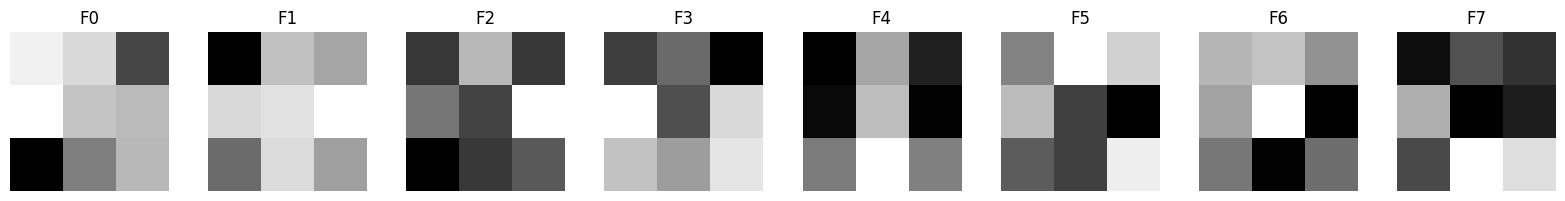

In [14]:
with torch.no_grad():
    w = cnn_model[0].weight.detach().cpu().clone()

w = w[:, 0, :, :]

fig, axes = plt.subplots(1, w.shape[0], figsize=(2*w.shape[0], 2))
for i, ax in enumerate(axes):
    ax.imshow(w[i], cmap="gray")
    ax.axis("off")
    ax.set_title(f"F{i}")

plt.tight_layout()
plt.show()


> **Interpretation note:** First-layer filters may resemble edges, lines, or contrast patterns, but not every learned filter has an obvious human-interpretable meaning. Describe only patterns that are actually visible in your trained model.


**Your answer — Tasks 5.1–5.2**

_Compare FFNN vs. CNN performance under the same learning rate and training protocol._

Task 5.1

Under the same training setup the CNN achieves higher validation and test accuracy ( 97.13%) compared to the FFNN (93.55%).

The filters are not identical, each has its own pattern of learned weights.

Task 5.2

1. The FFNN has total 101,770 trainable parameters.
2. The CNN has total 9,098 trainable parameters.
3. For a convolutional layer, $$
N_{\text{params}}
=
C_{\text{out}}
\left(
C_{\text{in}}k_Hk_W + 1
\right),
$$

 weights for first convolutional layer is  (8,1,3,3)

$$N
params
​
 =8×(1×3×3+1)=8×(9+1)=8×10=80$$

 PyTorch also providing the same output.

 4. The number of learned weights depends only on the kernel dimensions ($k_H \times k_W$), input channels ($C_{\text{in}}$), and output channels ($C_{\text{out}}$). Processing a larger spatial image ($64\times64$) simply slides the exact same kernel across more spatial locations, which increases runtime and activation memory but does not add extra trainable parameters.

 5. Weight sharing means the same set of weights (filter kernel) is reused across every local patch of the input image. In the first convolutional layer each filter reuses the same weights and bias at every spatial positions without increasing the number of trainable parameters.

 6. Final parameter counts:

Model    --- layer            	  -----------   Trainable parameters

FFNN -first linear layer	       ---- 100,480

FFNN -second linear layer	  ----     1,290

FFNN total: 101,770

CNN — first convolutional layer	  -- 80

CNN — second convolutional layer	- 1,168

CNN — final linear layer	 -        7,850

CNN total                   -       9,098

The CNN has approximately 11 times fewer trainable parameters than the FFNN .

## 6. Math Deep Dive — Convolution Arithmetic (Week 2)

For one spatial dimension,

$$
L_{\text{out}}
=
\left\lfloor
\frac{
L_{\text{in}} + 2p - k
}{
s
}
\right\rfloor
+1.
$$

For height,

$$
H_{\text{out}}
=
\left\lfloor
\frac{
H + 2p - k
}{
s
}
\right\rfloor
+1,
$$

and similarly for width.

Here:
- $k$ = kernel size,
- $s$ = stride,
- $p$ = padding.

### Worked example

For a $64\times64$ input with $k=3$, $s=2$, and $p=1$,

$$
H_{\text{out}}
=
\left\lfloor
\frac{64+2-3}{2}
\right\rfloor
+1
=
32.
$$

Thus the output spatial size is $32\times32$.

### Pooling

`nn.MaxPool2d(2)` uses a $2\times2$ window with stride $2$ by default, so it halves even spatial dimensions.

### Exercises

**Task 6.1**
Input $32\times32$, $k=3$, $s=1$, $p=1$. Compute the output size.

**Task 6.2**
Input $32\times32$, $k=5$, $s=2$, $p=0$. Compute the output size.

**Task 6.3**
An activation map has shape `(N, 8, 28, 28)` and is passed through `nn.MaxPool2d(2)`. What is the output shape?

**Task 6.4**
Trace the spatial size of the Section 5 CNN from $28\times28$ through both convolutions and pooling layers. Explain why the final linear layer receives $16\cdot7\cdot7$ inputs.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Sec. 7.3 (Padding and Stride)**: https://d2l.ai/

**Optional reading**
- Dumoulin & Visin, *A Guide to Convolution Arithmetic for Deep Learning*, arXiv:1603.07285.

In [15]:
x = torch.randn(1, 3, 64, 64)
conv = nn.Conv2d(3, 8, kernel_size=3, stride=2, padding=1)
print("Worked example:", conv(x).shape)

x2 = torch.randn(1, 1, 32, 32)
conv2 = nn.Conv2d(1, 4, kernel_size=5, stride=2, padding=0)
print("Task 6.2 verification:", conv2(x2).shape)

pool = nn.MaxPool2d(2)
x3 = torch.randn(4, 8, 28, 28)
print("Task 6.3 verification:", pool(x3).shape)

Worked example: torch.Size([1, 8, 32, 32])
Task 6.2 verification: torch.Size([1, 4, 14, 14])
Task 6.3 verification: torch.Size([4, 8, 14, 14])


**Your answer — Tasks 6.1–6.4**

_Show your calculations before checking the PyTorch output._

Task 6.1

For a convolutional layer $$H_{\text{out}} = \left\lfloor \frac{H + 2p - k}{s} \right\rfloor + 1$$
 Input 32×32, k=3, s=1, p=1


$$H_{\text{out}} = \left\lfloor \frac{32 + 2(1) - 3}{1} \right\rfloor + 1 = \left\lfloor \frac{31}{1} \right\rfloor + 1 = 31 + 1 = 32$$

Output size is 32 x 32.

Task 6.2

 Input 32×32, k=5, s=2, p=0

 $$H_{\text{out}} = \left\lfloor \frac{32 + 2(0) - 5}{2} \right\rfloor + 1 = \left\lfloor \frac{27}{2} \right\rfloor + 1 = \lfloor 13.5 \rfloor + 1 = 13 + 1 = 14$$

 Output size is 14 x 14.

 Task 6.3

 Input  shape (N, 8, 28, 28) .


 nn.MaxPool2d(2) uses a 2 × 2 pooling window with stride 2. It halves the height and width:
28/2=14.

The output shape is (N, 8, 14, 14).

Task 6.4

Input (N, 1, 28, 28) $\rightarrow$ Conv1 ($k=3, p=1, s=1$) $\rightarrow$ (N, 8, 28, 28)  
 MaxPool1(2) $\rightarrow$ (N, 8, 14, 14)   
 Conv2 ($k=3, p=1, s=1$) $\rightarrow$ (N, 16, 14, 14)   
 MaxPool2(2) $\rightarrow$ (N, 16, 7, 7)

 The second convolution produces 16 channels. After the second pooling layer, each channel has spatial dimensions of (7 x 7). The nn.Flatten() layer flattens everything except the batch dimension
N, providing $16 \cdot 7 \cdot 7$ features to the final linear layer.



## 7. Hyperparameters & Stability (Control Analogy)

Important hyperparameters include:
- **learning rate**,
- **batch size**,
- **model size**.

### Learning rate as a feedback-gain analogy

For

$$
J(w)
=
\frac{1}{2}\lambda w^2,
$$

gradient descent gives

$$
w_{t+1}
=
(1-\eta\lambda)w_t.
$$

Convergence requires

$$
|1-\eta\lambda|<1,
$$

so

$$
0<\eta<\frac{2}{\lambda}.
$$

This simplified example explains why a learning rate that is too large can lead to oscillation or divergence.

**Task 7.1 (Learning-rate experiment):**
- Train a fresh CNN for each learning rate in `{0.005, 0.05, 0.5}`.
- Keep seed and number of epochs fixed.
- Compare training loss and validation accuracy.
- Do not select the learning rate using the test set.

**Task 7.2 (Batch-size experiment):**
- Compare at least two batch sizes, e.g. `32` and `256`.
- Keep the other settings fixed.
- Compare runtime, validation accuracy, and the **per-step loss trace** logged during training.
- Use the per-step trace, not only three epoch averages, when discussing gradient noise or curve smoothness.


=== learning rate = 0.005 ===
Epoch 01 | train loss=1.5824 | val loss=0.6096 | val acc=78.50%
Epoch 02 | train loss=0.4020 | val loss=0.3660 | val acc=88.52%
Epoch 03 | train loss=0.3166 | val loss=0.3155 | val acc=90.36%
Runtime: 59.75 s

=== learning rate = 0.05 ===
Epoch 01 | train loss=0.4261 | val loss=0.2229 | val acc=92.44%
Epoch 02 | train loss=0.1275 | val loss=0.1073 | val acc=96.70%
Epoch 03 | train loss=0.0940 | val loss=0.1104 | val acc=96.44%
Runtime: 57.27 s

=== learning rate = 0.5 ===
Epoch 01 | train loss=0.4262 | val loss=1.1231 | val acc=73.40%
Epoch 02 | train loss=0.1029 | val loss=0.1005 | val acc=97.26%
Epoch 03 | train loss=0.0839 | val loss=0.3399 | val acc=91.82%
Runtime: 58.11 s


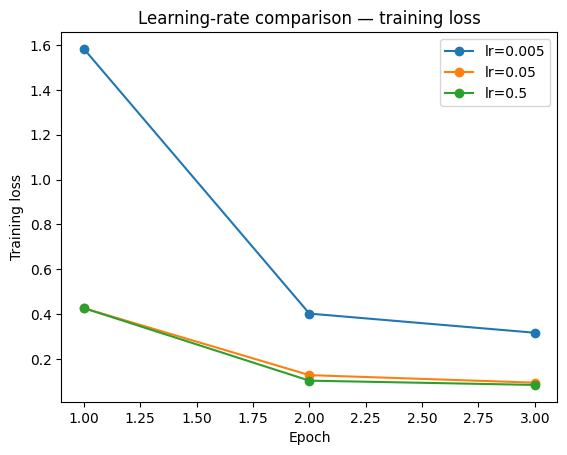

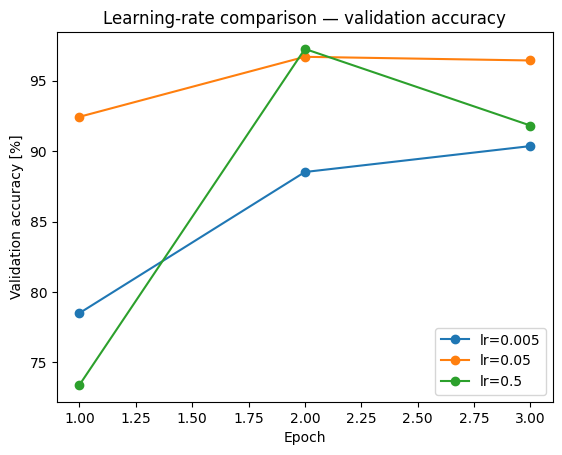

In [16]:
import time

lr_results = {}

for lr in [0.005, 0.05, 0.5]:
    print(f"\n=== learning rate = {lr} ===")
    start = time.perf_counter()

    _, hist = train_model(
        make_cnn,
        lr=lr,
        epochs=3,
        seed=SEED
    )

    elapsed = time.perf_counter() - start
    hist["runtime_s"] = elapsed
    lr_results[lr] = hist

    print(f"Runtime: {elapsed:.2f} s")

# Training loss
plt.figure()
for lr, hist in lr_results.items():
    plt.plot(
        range(1, len(hist["train_loss"]) + 1),
        hist["train_loss"],
        marker="o",
        label=f"lr={lr}"
    )
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Learning-rate comparison — training loss")
plt.legend()
plt.show()

# Validation accuracy
plt.figure()
for lr, hist in lr_results.items():
    plt.plot(
        range(1, len(hist["val_accuracy"]) + 1),
        [100*a for a in hist["val_accuracy"]],
        marker="o",
        label=f"lr={lr}"
    )
plt.xlabel("Epoch")
plt.ylabel("Validation accuracy [%]")
plt.title("Learning-rate comparison — validation accuracy")
plt.legend()
plt.show()


=== batch size = 32 ===
batch=32: runtime=62.29 s, val acc=97.36%

=== batch size = 256 ===
batch=256: runtime=52.77 s, val acc=94.84%


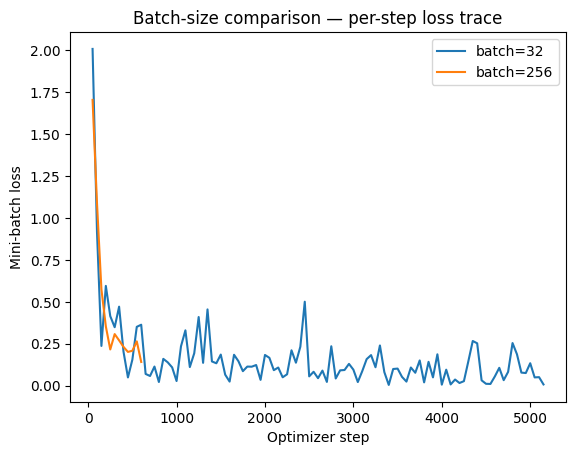

In [17]:
# Task 7.2 — batch-size comparison with per-step loss logging
def train_with_step_trace(model_fn, batch_size, lr=BASE_LR, epochs=3,
                          seed=SEED, log_every=50):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    train_loader_bs, val_loader_bs, _ = make_loaders(
        batch_size=batch_size,
        seed=seed
    )

    model = model_fn().to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)

    step_numbers = []
    step_losses = []
    global_step = 0

    start = time.perf_counter()

    for epoch in range(epochs):
        model.train()

        for X, y in train_loader_bs:
            X, y = X.to(device), y.to(device)

            logits = model(X)
            loss = loss_fn(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            global_step += 1

            if global_step % log_every == 0:
                step_numbers.append(global_step)
                step_losses.append(loss.item())

    elapsed = time.perf_counter() - start
    val_metrics = evaluate(model, val_loader_bs, loss_fn)

    return model, {
        "step": step_numbers,
        "step_loss": step_losses,
        "runtime_s": elapsed,
        "val_accuracy": val_metrics["accuracy"],
        "val_loss": val_metrics["loss"],
    }


batch_results = {}

for batch_size in [32, 256]:
    print(f"\n=== batch size = {batch_size} ===")

    _, result = train_with_step_trace(
        make_cnn,
        batch_size=batch_size,
        lr=BASE_LR,
        epochs=3,
        seed=SEED,
        log_every=50
    )

    batch_results[batch_size] = result

    print(
        f"batch={batch_size}: "
        f"runtime={result['runtime_s']:.2f} s, "
        f"val acc={100*result['val_accuracy']:.2f}%"
    )

plt.figure()
for batch_size, result in batch_results.items():
    plt.plot(
        result["step"],
        result["step_loss"],
        label=f"batch={batch_size}"
    )

plt.xlabel("Optimizer step")
plt.ylabel("Mini-batch loss")
plt.title("Batch-size comparison — per-step loss trace")
plt.legend()
plt.show()

### 7.3 Interpreting Training and Validation Behaviour

Typical patterns:

**Underfitting**
- training loss remains high,
- validation loss remains high.

**Useful learning**
- training loss decreases,
- validation loss also decreases.

**Overfitting**
- training loss continues decreasing,
- validation loss stops improving or increases.

With only three epochs on full MNIST, overfitting may not be visible.

**Task 7.3 (Optional overfitting demonstration):**
- Use a small training subset of roughly 2,000 examples.
- Use the larger FFNN scaffold below and train for about 20–30 epochs.
- Plot training and validation loss.
- Describe whether/when validation performance stops improving.

> **Hint:** If the train/validation gap is not clearly visible with plain SGD, try `optimizer_name="adam"` with a small learning rate such as `0.001`. The goal is to observe a generalization gap, not to force overfitting at a fixed epoch.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 5** and **Ch. 12**.
- Géron, *Hands-On Machine Learning*, **Ch. 10–11**.

**Optional reading**
- Goodfellow et al., *Deep Learning*, **Ch. 7, 8, and 11**.
- Prince, *Understanding Deep Learning*, **Ch. 6, 8, and 9**.

Epoch 01 | train loss=1.3008 | val loss=0.5483 | val acc=83.54%
Epoch 02 | train loss=0.4658 | val loss=0.4504 | val acc=86.12%
Epoch 03 | train loss=0.3234 | val loss=0.3902 | val acc=88.02%
Epoch 04 | train loss=0.2313 | val loss=0.3539 | val acc=89.46%
Epoch 05 | train loss=0.1626 | val loss=0.3429 | val acc=90.02%
Epoch 06 | train loss=0.1247 | val loss=0.3509 | val acc=90.02%
Epoch 07 | train loss=0.0922 | val loss=0.3591 | val acc=90.36%
Epoch 08 | train loss=0.0590 | val loss=0.3528 | val acc=90.62%
Epoch 09 | train loss=0.0421 | val loss=0.3583 | val acc=90.44%
Epoch 10 | train loss=0.0479 | val loss=0.3927 | val acc=90.40%
Epoch 11 | train loss=0.0274 | val loss=0.3720 | val acc=90.76%
Epoch 12 | train loss=0.0161 | val loss=0.3791 | val acc=91.12%
Epoch 13 | train loss=0.0111 | val loss=0.3905 | val acc=90.90%
Epoch 14 | train loss=0.0087 | val loss=0.3889 | val acc=90.92%
Epoch 15 | train loss=0.0067 | val loss=0.3992 | val acc=91.02%
Epoch 16 | train loss=0.0049 | val loss=

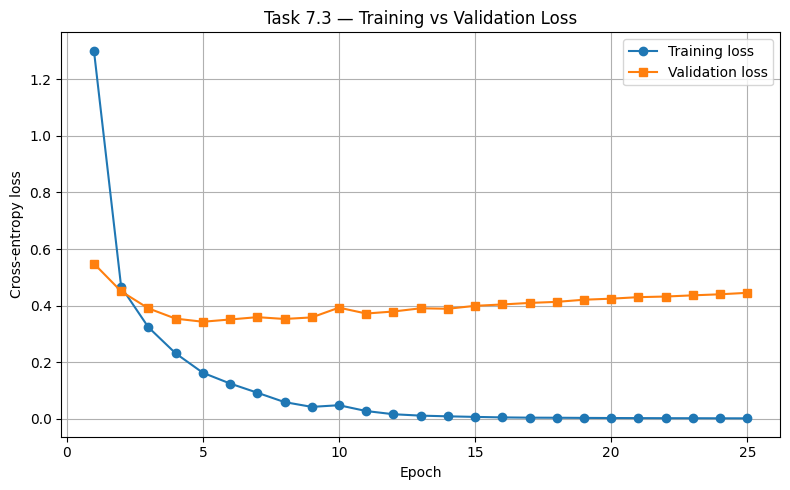

Best validation-loss epoch: 5
Minimum validation loss: 0.3429
Final training loss: 0.0016
Final validation loss: 0.4452


In [21]:

# Task 7.3 — Overfitting demonstration

from torch.utils.data import Subset, DataLoader
import matplotlib.pyplot as plt
import torch


small_indices = torch.randperm(
    len(train_ds),
    generator=torch.Generator().manual_seed(SEED)
)[:2000].tolist()

small_train_ds = Subset(train_ds, small_indices)


small_train_loader = DataLoader(
    small_train_ds,
    batch_size=64,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0
)


def make_overfit_ffnn():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 512),
        nn.ReLU(),
        nn.Linear(512, 256),
        nn.ReLU(),
        nn.Linear(256, 10)
    )


overfit_model, overfit_history = train_model(
    make_overfit_ffnn,
    lr=0.001,
    epochs=25,
    seed=SEED,
    optimizer_name="adam",
    train_loader=small_train_loader,
    val_loader=val_loader
)


epochs = range(1, len(overfit_history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    overfit_history["train_loss"],
    marker="o",
    label="Training loss"
)
plt.plot(
    epochs,
    overfit_history["val_loss"],
    marker="s",
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Task 7.3 — Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


best_epoch = (
    overfit_history["val_loss"].index(
        min(overfit_history["val_loss"])
    ) + 1
)

print("Best validation-loss epoch:", best_epoch)
print(
    "Minimum validation loss:",
    f"{min(overfit_history['val_loss']):.4f}"
)
print(
    "Final training loss:",
    f"{overfit_history['train_loss'][-1]:.4f}"
)
print(
    "Final validation loss:",
    f"{overfit_history['val_loss'][-1]:.4f}"
)


**Your answer — Tasks 7.1–7.3**

_Describe optimization stability, validation behaviour, and any evidence of underfitting or overfitting._

Task 7.1

lr = 0.005 (Under-shooting / Slow): Loss decreases steadily from 1.5824  to  0.3166, reaching $90.36\%$ validation accuracy by Epoch 3.   

lr = 0.05 (Optimal): Loss drops quickly to $0.0940$, achieving a high and stable validation accuracy of $96.44\%$ ($96.70\%$ peak in Epoch 2) with low validation loss ($0.1104$).  

lr = 0.5 (Over-shooting / Unstable): Validation loss spikes from $0.1005$ to $0.3399$ between Epochs 2 and 3, causing validation accuracy to drop from $97.26\%$ to $91.82\%$.


Task 7.2

Batch = 32 (Higher Accuracy, Noisier Trace):

Runtime: Takes 61.99 s.   
Validation Accuracy: Achieves 97.36%.  
Optimizer Steps & Trace Behavior: Completes over 5,000 steps across the 3 epochs.The per-step loss trace shows high variance and frequent fluctuations.





Batch = 256 (Faster Computation, Smoother Trace):

Runtime: Takes 52.20 s (about 10 seconds faster).

Validation Accuracy: Achieves 94.84%.  
  
Optimizer Steps & Trace Behavior:   The curve is much smoother and flatter. But it takes far fewer parameter update steps with the same fixed learning rate.

Task 7.3

Validation performance stops improving after epoch 5, when the validation loss reaches its minimum of 0.3429. After that, validation loss generally increases, reaching 0.4452 at epoch 25, while training loss continues to decrease. This indicates that the model begins to overfit the training data after approximately epoch 5.

## 8. Scientific Work Style

Record:
- dataset and preprocessing,
- train/validation/test split,
- random seed,
- architecture,
- optimizer,
- learning rate,
- batch size,
- epochs,
- software versions,
- plots and metrics,
- Git commit.

For stricter reproducibility where supported:

```python
torch.use_deterministic_algorithms(True)
```

On CUDA, some deterministic matrix-multiplication paths also require the environment variable

```bash
CUBLAS_WORKSPACE_CONFIG=:4096:8
```

to be set **before starting Python**. Deterministic mode can reduce performance and some operations may still be unavailable in deterministic form.

Exact reproducibility can still depend on hardware, CUDA/cuDNN versions, and selected operations.

**Task 8.1:**
- Repeat a short experiment with the same seed.
- Change only the seed and repeat.
- Report how much the final validation accuracy changes.

**Core reading**
- Goodfellow et al., *Deep Learning*, **Ch. 11**.

**Optional reading**
- Paszke et al. (2019), PyTorch paper.
- Pointer, *Programming PyTorch for Deep Learning*, **Ch. 1 and 7**.

### 8.2 GitHub workflow

Recommended repository structure:

```text
/
├── .gitignore
├── requirements.txt
├── Notebook_1_Deep_Learning_Fundamentals.ipynb
├── README.md
└── reports/
    └── fundamentals_experiment_log.md
```

Create a `.gitignore` **before** the first `git add .`:

```gitignore
data/
.ipynb_checkpoints/
__pycache__/
```

This is important because MNIST is downloaded into `./data/`. The dataset should **not** be committed to Git; it can be downloaded again by the notebook.

A minimal `requirements.txt` for this notebook can contain:

```text
numpy
matplotlib
torch
torchvision
```

If your environment requires fixed versions, record them explicitly, for example:

```text
numpy==...
matplotlib==...
torch==...
torchvision==...
```

For this small lab, avoid exporting a large unrelated base environment. Inspect only the relevant packages, for example:

```bash
python -m pip list | grep -Ei "torch|torchvision|numpy|matplotlib"
```

If you work with Conda and created a dedicated environment, a concise alternative is:

```bash
conda env export --from-history > environment.yml
```

Then use the normal Git workflow:

```bash
git status
git add .
git status
git commit -m "Complete deep learning fundamentals experiments"
git push
git tag v0.1-fundamentals
git push origin v0.1-fundamentals
```

> Always inspect `git status` after `git add .` and verify that `data/` is **not staged**.

### 8.3 Experiment-log template

```markdown
# Deep Learning Fundamentals — Experiment Log

## Environment
- Python:
- PyTorch:
- Device:
- Seed:

## Dataset and preprocessing
- Dataset:
- Train/validation/test split:
- Input transformation:

## Model
- Architecture:
- FFNN parameter count:
- CNN parameter count:

## Training configuration
- Optimizer:
- Learning rate:
- Batch size:
- Epochs:

## Results
- Final training loss:
- Final validation accuracy:
- Final test accuracy:
- Relevant plots:

## Interpretation
- Evidence of underfitting/overfitting:
- Optimization stability:
- Effect of architecture / weight sharing:
- Main comparison:
- Limitations:
```

**Task 8.2:**
- Create `.gitignore` before staging files.
- Add `requirements.txt` (or alternatively an `environment.yml` if you use Conda).
- Complete the one-page experiment log.
- Push notebook, environment specification, and report.
- Tag the final commit as `v0.1-fundamentals`.

**Your answer — Section 8**

_Note the final Git commit/tag here._

Task 8.1

With the same seed (42), the final validation accuracy was identical: 96.44%.

Changing only the seed changed the final validation accuracy slightly.

The values ranged from 96.18% to 96.72%.

The maximum change was 0.54 percentage points (between seed 123 and seed 7).

Compared with seed 42, seed 123 differed by 0.26 pp and seed 7 differed by 0.28 pp.

Task 8.2


# Deep Learning Fundamentals — Experiment Log

## Environment
- Python: 3.13.16
- PyTorch: 2.11.0+cpu
- torchvision: 0.26.0+cpu
- Device: CPU
- Seed: 42

## Dataset and preprocessing
- Dataset: MNIST
- Train/validation/test split: 55,000 / 5,000 / 10,000
- Input transformation: ToTensor() — pixel values scaled to [0, 1]

## Model
- FFNN architecture: Flatten → Linear(784,128) → ReLU → Linear(128,10)
- FFNN parameter count: 101,770
- CNN architecture: Conv2d(1,8,3,p=1) → ReLU → MaxPool2d(2) → Conv2d(8,16,3,p=1) → ReLU → MaxPool2d(2) → Flatten → Linear(16*7*7,10)
- CNN parameter count: 9,098
- First conv layer parameters: 80 (weight 8×1×3×3 = 72, bias 8)

## Training configuration
- Optimizer: SGD (unless stated otherwise)
- Learning rate: 0.05 (base)
- Batch size: 64 (base)
- Epochs: 3 (base)

## Results
- FFNN final test accuracy: 93.55%
- CNN final test accuracy: 97.13%
- CNN validation accuracy (base): 96.44% (epoch 3), peak 96.70% (epoch 2)
- FFNN validation accuracy (base): 92.90% (epoch 3)

### Learning-rate comparison (CNN, 3 epochs)
- lr = 0.005: val acc 90.36%, train loss 0.3166 (stable but slow)
- lr = 0.05: val acc 96.44%, train loss 0.0940 (stable and effective)
- lr = 0.5: val acc 91.82%, val loss 0.3399 (unstable, over-shooting)

### Batch-size comparison (CNN, 3 epochs)
- batch = 32: runtime 62.29 s, val acc 97.36%, noisier per-step loss trace
- batch = 256: runtime 52.77 s, val acc 94.84%, smoother per-step loss trace

### Overfitting demonstration (FFNN 512-256, Adam lr=0.001, 2000 training samples, 25 epochs)
- Best validation loss: 0.3429 at epoch 5
- Final training loss: 0.0016
- Final validation loss: 0.4452
- Clear overfitting after epoch 5

## Interpretation
- Evidence of underfitting/overfitting: Overfitting observed in the small-data experiment after epoch 5.
- Optimization stability: lr = 0.5 caused instability; lr = 0.05 was stable and effective; lr = 0.005 was slow but stable.
- Effect of architecture / weight sharing: CNN achieved higher accuracy (97.13% vs 93.55%) with far fewer parameters (9,098 vs 101,770) due to weight sharing and local receptive fields.
- Main comparison: CNN outperformed FFNN under the same learning rate and training protocol.
- Limitations: Only 3 epochs for base models; single seed for most experiments.



---
# Optional Extension / Week 3

## 9. Losses, Metrics & Optimizers

This section is **not required for the two-week fundamentals block**.

### 9.1 Loss vs. metric

For multiclass classification,

$$
\mathcal{L}
=
-\sum_{k=1}^{K} y_k\log(p_k).
$$

Accuracy is

$$
\mathrm{Accuracy}
=
\frac{\text{correct predictions}}{N}.
$$

A model can improve cross-entropy loss without changing accuracy because the predicted class may stay the same while confidence changes.

### 9.2 Confusion matrix, precision, recall, and F1

For one selected class in a one-vs-rest view,

$$
\mathrm{Precision}
=
\frac{TP}{TP+FP},
$$

$$
\mathrm{Recall}
=
\frac{TP}{TP+FN},
$$

$$
F_1
=
2
\frac{
\mathrm{Precision}\cdot\mathrm{Recall}
}{
\mathrm{Precision}+\mathrm{Recall}
}.
$$

MNIST is **approximately balanced**, so accuracy is a useful first summary, but a confusion matrix reveals which digits are confused.

### 9.3 Optimizer update

Basic gradient descent uses

$$
\theta_{t+1}
=
\theta_t
-
\eta
\frac{\partial\mathcal{L}}{\partial\theta_t}.
$$

**Optional tasks**
- Build a confusion matrix for MNIST.
- Compute precision, recall, and F1 for one selected digit.
- Compare SGD and Adam under the same architecture, seed, and epoch count.

**Core reading**
- Zhang et al., *Dive into Deep Learning*, **Ch. 4 and Ch. 12**.

**Optional reading**
- Goodfellow et al., *Deep Learning*, **Ch. 6, 8, and 11**.
- Géron, *Hands-On Machine Learning*, **Ch. 10–11**.
- Prince, *Understanding Deep Learning*, **Ch. 5, 6, and 8**.

---
## 10. Self-Study Reading Map

You are **not expected to read every source from beginning to end**.

### Core sources for the 2-week block

**Dive into Deep Learning — Zhang et al.**
- Ch. 2 — Preliminaries
- Ch. 4 — Linear Neural Networks for Classification
- Ch. 5 — Multilayer Perceptrons
- Ch. 7 — Convolutional Neural Networks
- Sec. 8.2 — VGG
- Ch. 12 — Optimization Algorithms  
https://d2l.ai/

**Géron — Hands-On Machine Learning, 3rd ed.**
- Ch. 10 — Introduction to Artificial Neural Networks
- Ch. 11 — Training Deep Neural Networks
- Ch. 14 — Deep Computer Vision / CNNs

### Optional depth

**Goodfellow, Bengio & Courville — Deep Learning**
- Ch. 2 — Linear Algebra
- Ch. 4 — Numerical Computation
- Ch. 6 — Deep Feedforward Networks
- Ch. 7 — Regularization
- Ch. 8 — Optimization
- Ch. 9 — Convolutional Networks
- Ch. 11 — Practical Methodology  
https://www.deeplearningbook.org/

**Prince — Understanding Deep Learning**
- **Appendix B** — Mathematics
- **Appendix C** — Probability
- Ch. 2 — Supervised Learning
- Ch. 3 — Shallow Neural Networks
- Ch. 4 — Deep Neural Networks
- Ch. 5 — Loss Functions
- Ch. 6 — Fitting Models
- Ch. 7 — Gradients and Initialization
- Ch. 8 — Measuring Performance
- Ch. 9 — Regularization
- Ch. 10 — Convolutional Networks  
https://udlbook.github.io/udlbook/

**Paszke et al. (2019) — PyTorch**
- Research/system paper: autograd, dynamic computation graphs, and PyTorch design.  
https://arxiv.org/abs/1912.01703

**Pointer — Programming PyTorch for Deep Learning**
- Ch. 1 — Getting Started
- Ch. 2 — Image Classification
- Ch. 3 — CNNs
- Ch. 7 — Debugging

**Bengio (2013) — Deep Learning of Representations: Looking Forward**
- Research survey on representation learning.  
https://arxiv.org/abs/1305.0445

### Self-study cycle

1. **Run** the example.
2. **Predict** what a change should do.
3. **Change one factor**.
4. **Observe** the result.
5. **Explain** it using a reference.
6. **Record** the configuration and evidence.

### Questions you should be able to answer after two weeks

1. Why are nonlinear activations necessary?
2. Why does `CrossEntropyLoss` expect logits?
3. How does the chain rule produce backpropagation?
4. Why is PyTorch's `Linear.weight` shape transposed relative to the row-vector notation?
5. Why does weight sharing reduce CNN parameter count? Use your result from **Task 5.2** as evidence.
6. How do kernel size, padding, stride, and pooling change feature-map size?
7. Why can training loss decrease while validation performance gets worse?
8. How does the learning rate affect optimization stability?
9. Why should hyperparameters be selected on validation data rather than the test set?
10. What information must be recorded to make an experiment reproducible?